# OM065ShortProject-SeattleBicycle

1. Import the data

In [8]:
# import libraries
library(ggplot2)
library(scales)

# import data
FremontBridge <- read.csv("FremontBridge.csv", header = TRUE)
str(FremontBridge)
dim(FremontBridge)   # observations, variables

'data.frame':	29880 obs. of  3 variables:
 $ Date                        : chr  "10/03/2012 12:00:00 AM" "10/03/2012 01:00:00 AM" "10/03/2012 02:00:00 AM" "10/03/2012 03:00:00 AM" ...
 $ Fremont.Bridge.West.Sidewalk: int  4 4 1 2 6 21 105 257 291 172 ...
 $ Fremont.Bridge.East.Sidewalk: int  9 6 1 3 1 10 50 95 146 104 ...


[1] 29880     3

2. Clean the data

a) Convert the dates into a usable format

In [10]:
FremontBridge$Date <- as.POSIXct(strptime(FremontBridge$Date,
"%m/%d/%Y %I:%M:%S %p", tz = "PST8PDT")) # in Seattle
FremontBridge$Weekday<- weekdays(FremontBridge$Date)
FremontBridge$Weekday<- as.Date(FremontBridge$Date)

b) Rename the columns to the shorter "West" and "East", set any missing values to zero, and add a "Total" column.

In [11]:
FremontBridge$East <- FremontBridge$Fremont.Bridge.East.Sidewalk
FremontBridge$West <- FremontBridge$Fremont.Bridge.West.Sidewalk
FremontBridge$East[is.na(FremontBridge$East)] <- as.integer(0)
FremontBridge$West[is.na(FremontBridge$West)] <- as.integer(0)
FremontBridge$Total <- FremontBridge$East + FremontBridge$West

c) Aggregate the counts to have hourly, weekly and monthly totals.

In [16]:
FremontBridge$hour <- format(FremontBridge$Date, "%H")
FremontBridge$dates <- as.Date(FremontBridge$Date, tz = "PST8PDT")
FremontBridge$week <- as.Date(cut(FremontBridge$Date,breaks = "week", start.on.monday = TRUE)) # weekly break point to Monday (default)
FremontBridge$month <- as.Date(cut(FremontBridge$Date, breaks = "month"))

3. Visualize the data


a) Create 3 plots of the data by weeks to show the number (as a weekly histogram)
of the West, East and Total bicycle travelers across the Fremont Bridge.

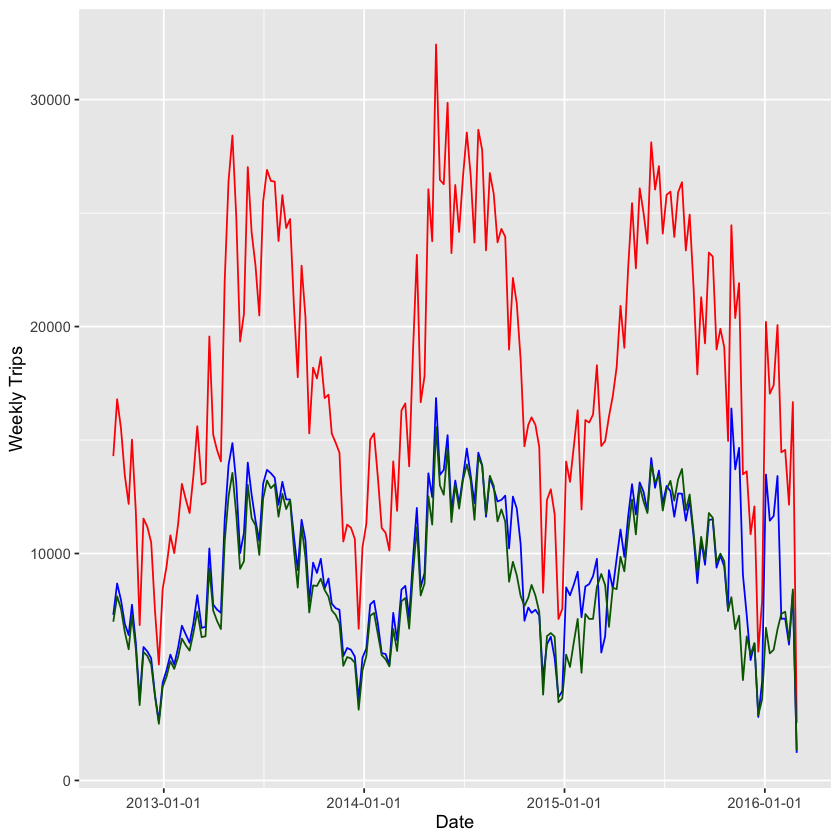

In [18]:
ggplot(FremontBridge)+stat_summary(aes(x=week, y=Total), fun.y = sum, geom = "line", color = "red") + stat_summary(aes(x=week,y=West), fun.y = sum, geom = "line", color = "blue") + stat_summary(aes(x=week,y=East), fun = sum, geom = "line", color = "darkgreen") + scale_x_date(breaks = date_breaks(width = "1 year")) + xlab("Date") + ylab("Weekly Trips") # fun.y deprecated, use fun instead

In [ ]:
# a) Convert the dates
FremontBridge$Date <- as.POSIXct(strptime(FremontBridge$Date,
                                          "%m/%d/%Y %I:%M:%S %p", tz = "PST8PDT"))
FremontBridge$Weekday <- weekdays(FremontBridge$Date)

# b) Rename columns, set missing values to zero, add Total
FremontBridge$East <- FremontBridge$Fremont.Bridge.East.Sidewalk
FremontBridge$West <- FremontBridge$Fremont.Bridge.West.Sidewalk
FremontBridge$East[is.na(FremontBridge$East)] <- 0L
FremontBridge$West[is.na(FremontBridge$West)] <- 0L
FremontBridge$Total <- FremontBridge$East + FremontBridge$West

# c) Hourly, weekly and monthly groupings
FremontBridge$hour  <- format(FremontBridge$Date, "%H")
FremontBridge$dates <- as.Date(FremontBridge$Date, tz = "PST8PDT")
FremontBridge$week  <- as.Date(cut(FremontBridge$dates, breaks = "week",
                                   start.on.monday = TRUE))  # week starts Monday
FremontBridge$month <- as.Date(cut(FremontBridge$dates, breaks = "month"))
str(FremontBridge)

'data.frame':	29880 obs. of  11 variables:
 $ Date                        : POSIXct, format: "2012-10-03 00:00:00" "2012-10-03 01:00:00" ...
 $ Fremont.Bridge.West.Sidewalk: int  4 4 1 2 6 21 105 257 291 172 ...
 $ Fremont.Bridge.East.Sidewalk: int  9 6 1 3 1 10 50 95 146 104 ...
 $ Weekday                     : chr  "Wednesday" "Wednesday" "Wednesday" "Wednesday" ...
 $ East                        : int  9 6 1 3 1 10 50 95 146 104 ...
 $ West                        : int  4 4 1 2 6 21 105 257 291 172 ...
 $ Total                       : int  13 10 2 5 7 31 155 352 437 276 ...
 $ hour                        : chr  "00" "01" "02" "03" ...
 $ dates                       : Date, format: "2012-10-03" "2012-10-03" ...
 $ week                        : Date, format: "2012-10-01" "2012-10-01" ...
 $ month                       : Date, format: "2012-10-01" "2012-10-01" ...


b) The above histograms are hard to read so make the graph look nicer and plot both
directions counts and the total on the same graph:

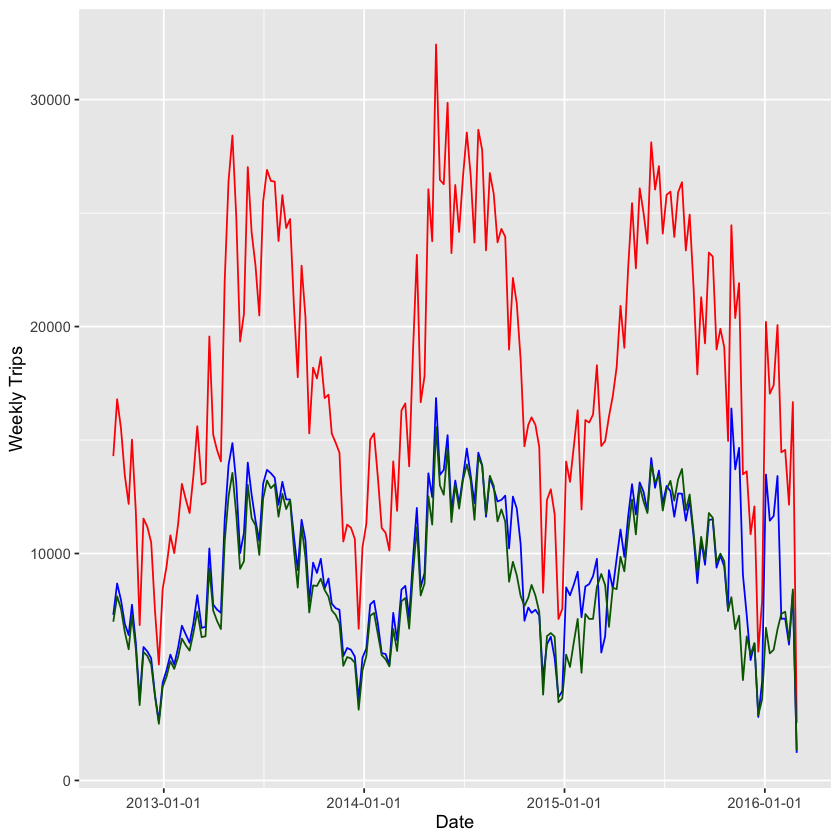

In [19]:
ggplot(FremontBridge) + stat_summary(aes(x=week, y=Total), fun.y = sum, # adds up all observations for the total
geom = "line", color = "red") + stat_summary(aes(x=week,y=West), fun.y = sum, # adds up all observations for the west
geom = "line", color = "blue") + stat_summary(aes(x=week,y=East), fun.y = sum, # adds up all observations for the east
geom = "line", color = "darkgreen") + scale_x_date(breaks = date_breaks(width = "1 year")) +
xlab("Date") +
ylab("Weekly Trips")

4. Prepare the data for ML

In [22]:
FremontBridgePivot <- read.csv("FremontBridgePivotnoTotals.csv", header = TRUE)
FremontBridgePivot$date <- as.Date(FremontBridgePivot$date, format = "%m/%d/%Y")
dim(FremontBridgePivot)
head(FremontBridgePivot[, 1:8])

[1] 1245   77

,X,date,East00,West00,Total00,East01,West01,Total01
,<int>,<date>,<int>,<int>,<int>,<int>,<int>,<int>
1,1,2012-10-03,9,4,13,6,4,10
2,2,2012-10-04,11,7,18,0,3,3
3,3,2012-10-05,7,4,11,4,4,8
4,4,2012-10-06,7,8,15,5,10,15
5,5,2012-10-07,5,6,11,5,12,17
6,6,2012-10-08,5,4,9,2,2,4


5. Principal Component Analysis

[1] 1245   48

Importance of components:
                          PC1    PC2     PC3     PC4     PC5     PC6     PC7
Standard deviation     4.4084 3.0988 1.39726 1.36977 1.29264 1.22168 1.07815
Proportion of Variance 0.4049 0.2001 0.04067 0.03909 0.03481 0.03109 0.02422
Cumulative Proportion  0.4049 0.6049 0.64559 0.68468 0.71949 0.75059 0.77480
                           PC8     PC9    PC10    PC11    PC12    PC13    PC14
Standard deviation     0.99960 0.94957 0.89459 0.88251 0.83637 0.79347 0.76313
Proportion of Variance 0.02082 0.01879 0.01667 0.01623 0.01457 0.01312 0.01213
Cumulative Proportion  0.79562 0.81440 0.83108 0.84730 0.86188 0.87499 0.88713
                          PC15    PC16    PC17    PC18    PC19    PC20    PC21
Standard deviation     0.74660 0.70167 0.66662 0.64771 0.61823 0.58651 0.51663
Proportion of Variance 0.01161 0.01026 0.00926 0.00874 0.00796 0.00717 0.00556
Cumulative Proportion  0.89874 0.90900 0.91825 0.92699 0.93496 0.94212 0.94768
                          PC22    

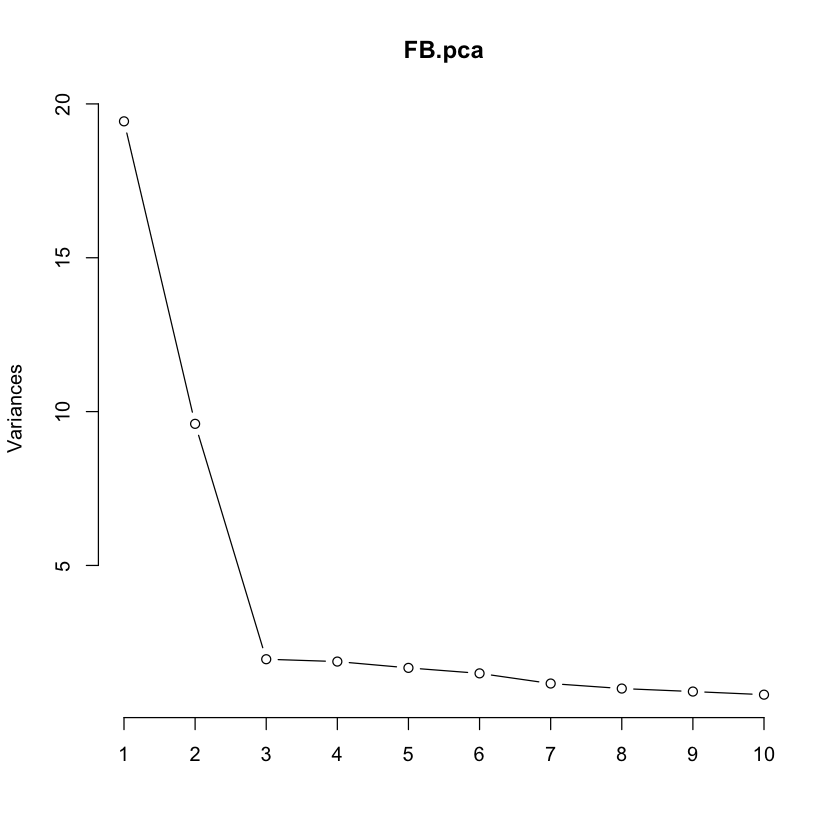

[1] 0.405 0.605 0.646 0.685 0.719 0.751

[1] 7

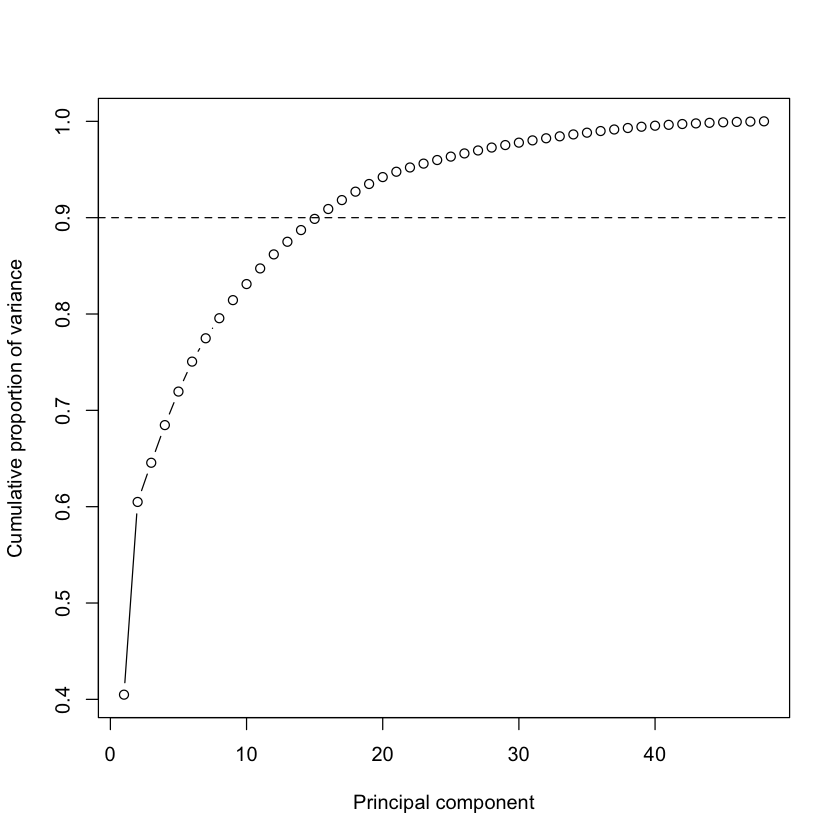

In [26]:
# The pivot file also contains Total columns and daily totals, so select only the
# 48 hourly East/West columns by name (not by position).
FB.hours <- FremontBridgePivot[, grep("^(East|West)[0-9]{2}$", names(FremontBridgePivot))]
dim(FB.hours)   # expect 48 columns

FB.pca <- prcomp(FB.hours, center = TRUE, scale. = TRUE)
plot(FB.pca, type = "l")
summary(FB.pca)

# Scree / cumulative variance to choose how many PCs to keep
var_explained <- FB.pca$sdev^2 / sum(FB.pca$sdev^2)
plot(cumsum(var_explained), type = "b", xlab = "Principal component",
     ylab = "Cumulative proportion of variance")
abline(h = 0.9, lty = 2)
round(cumsum(var_explained)[1:6], 3)
sum(FB.pca$sdev^2 > 1)   # Kaiser criterion: components with eigenvalue > 1

6. More Visualizations and Conclusions

Warning message:
“`qplot()` was deprecated in ggplot2 3.4.0.”


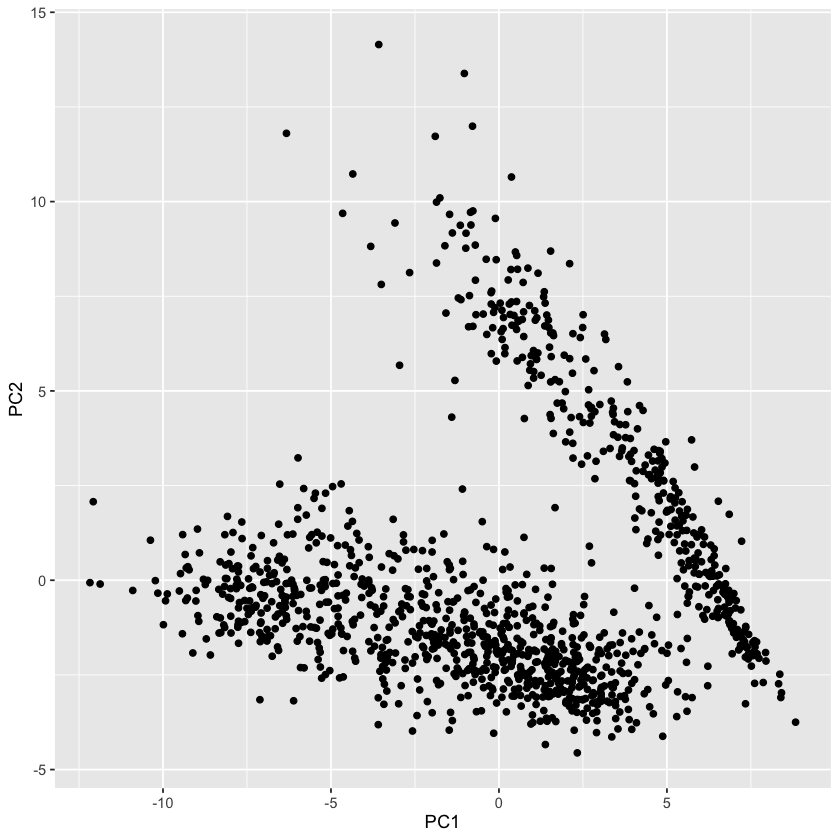

In [6]:
# 6a. PC1 vs PC2 scatterplot
scores <- data.frame(FB.pca$x[, 1:3])
qplot(x = PC1, y = PC2, data = scores)

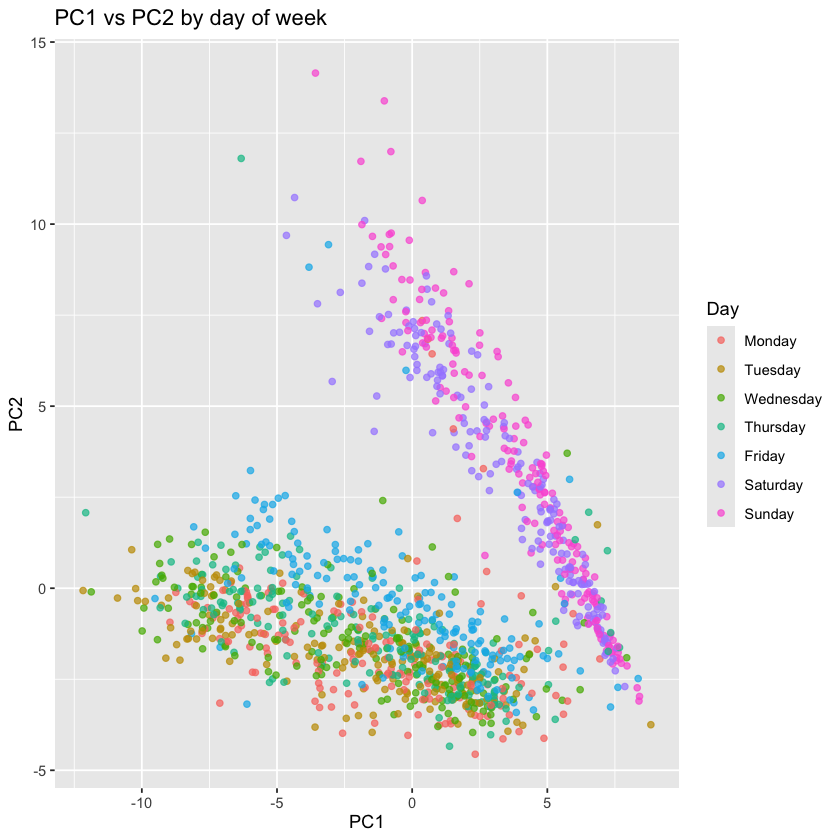

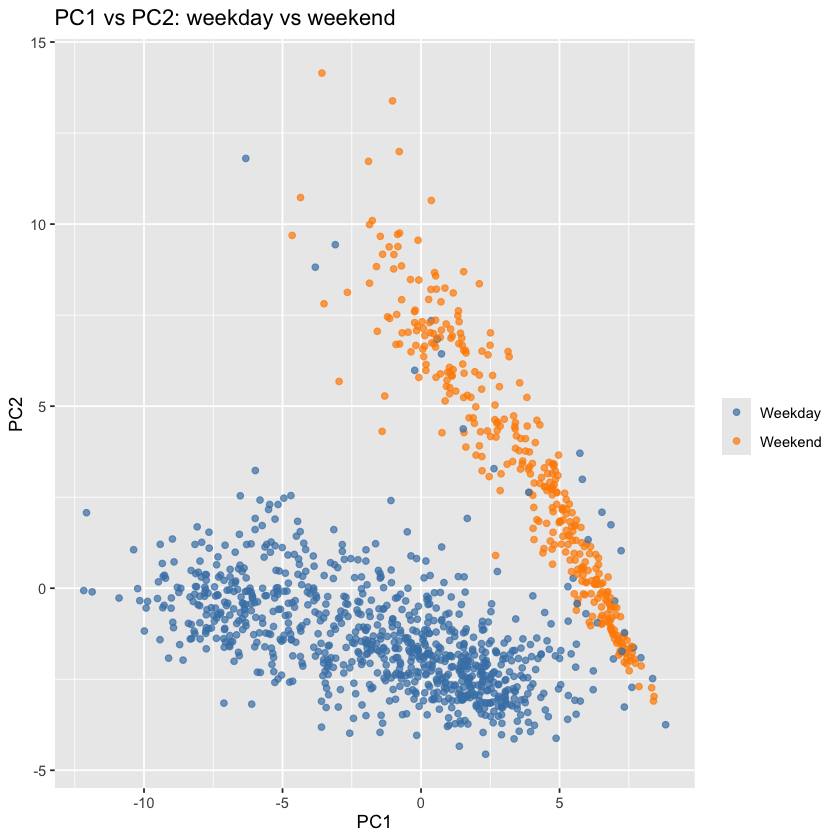

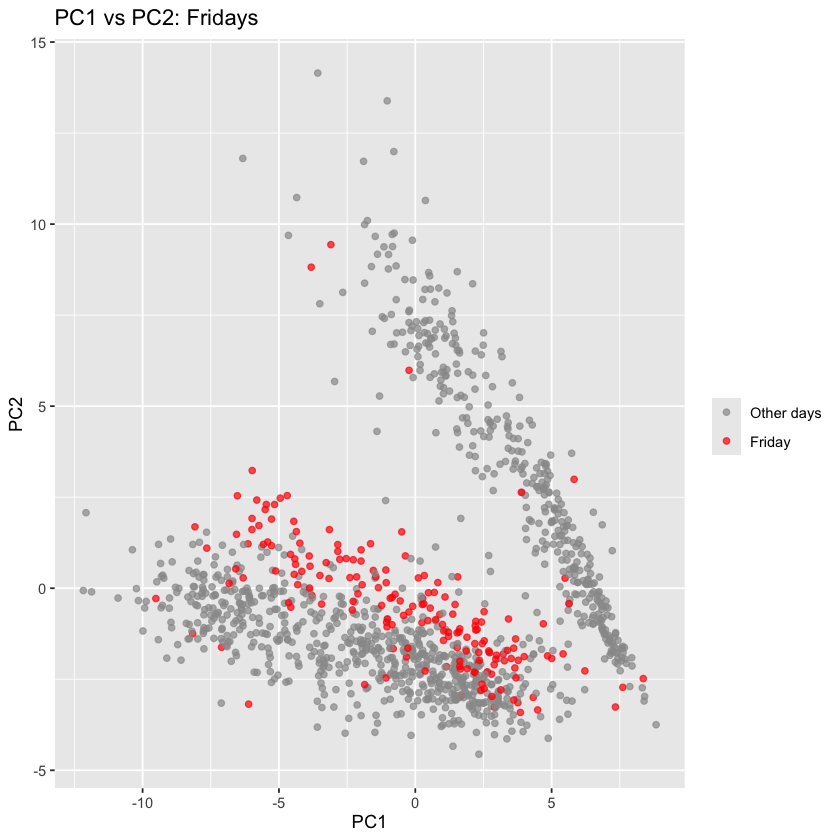

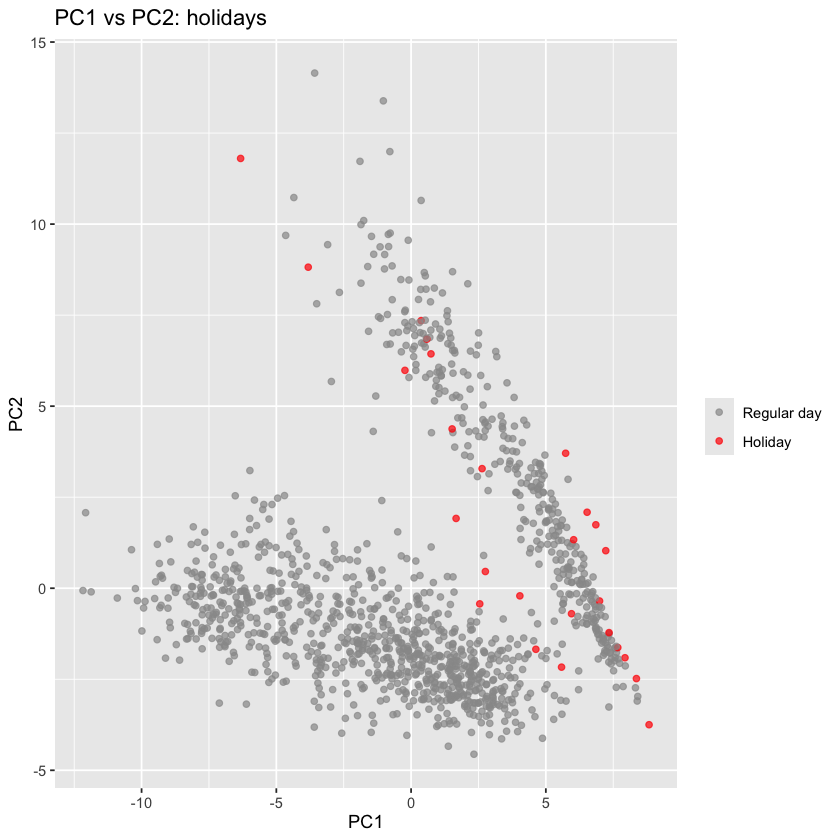

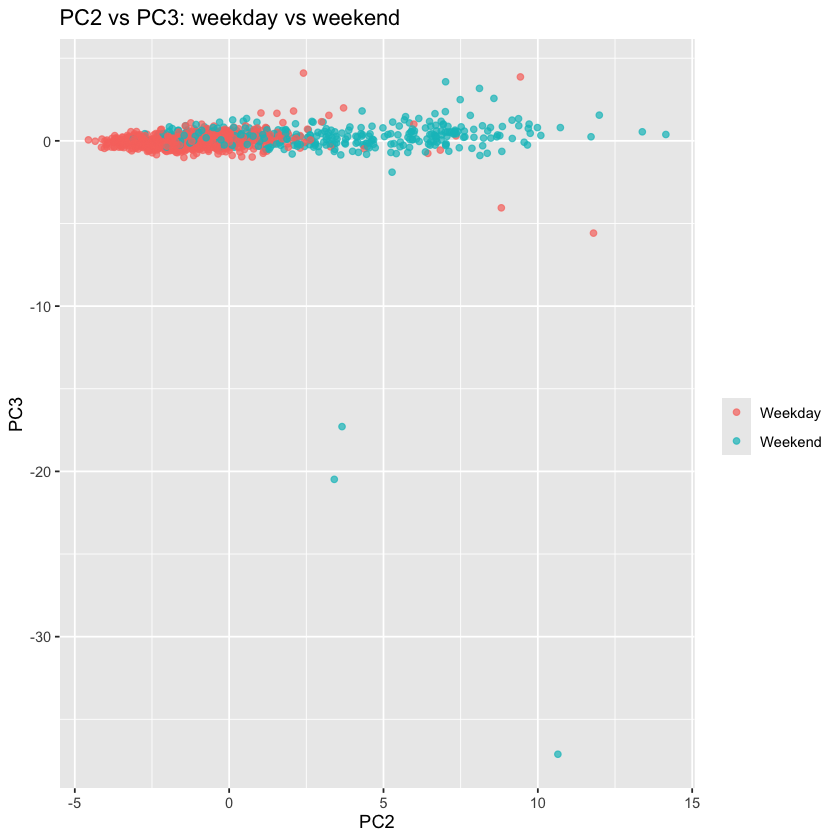

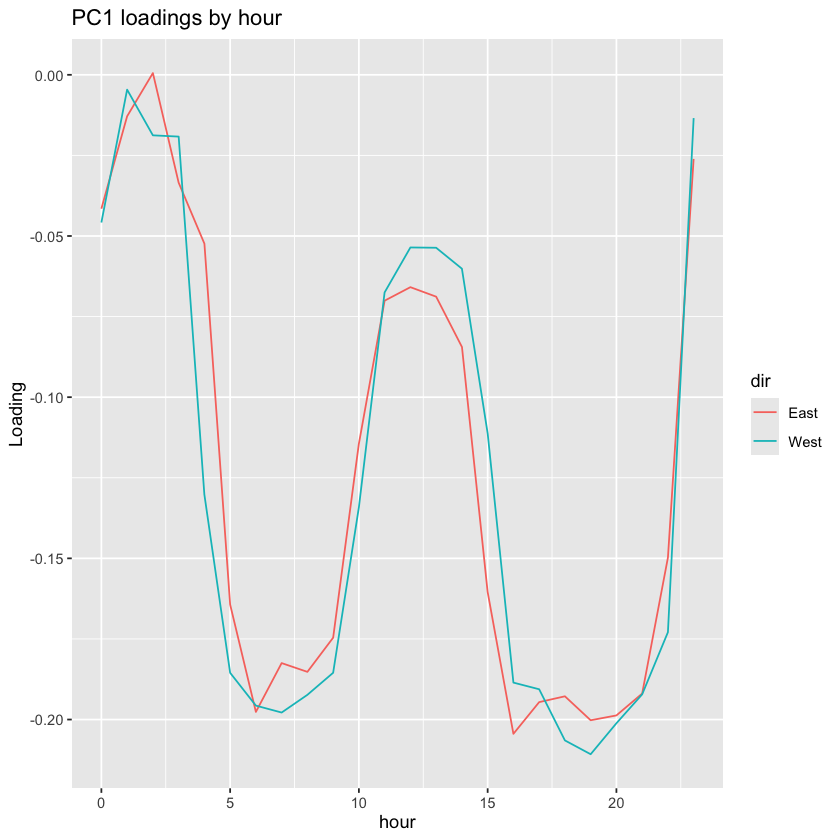

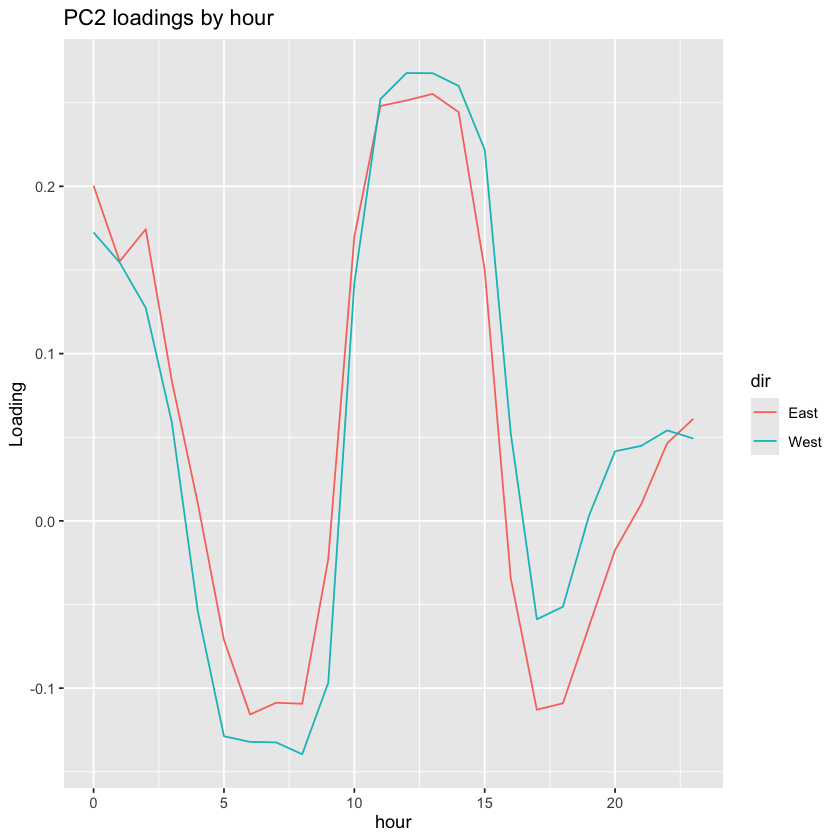

In [7]:
# 6b. Color the scores by meaningful groupings
scores$date <- as.Date(FremontBridgePivot$date)
scores$weekday <- factor(weekdays(scores$date),
                         levels = c("Monday","Tuesday","Wednesday","Thursday",
                                    "Friday","Saturday","Sunday"))
scores$daytype <- ifelse(scores$weekday %in% c("Saturday","Sunday"), "Weekend", "Weekday")

# Day of the week
ggplot(scores, aes(PC1, PC2, colour = weekday)) + geom_point(alpha = 0.7) +
  labs(title = "PC1 vs PC2 by day of week", colour = "Day")

# Weekday vs weekend
ggplot(scores, aes(PC1, PC2, colour = daytype)) + geom_point(alpha = 0.7) +
  scale_colour_manual(values = c(Weekday = "steelblue", Weekend = "darkorange")) +
  labs(title = "PC1 vs PC2: weekday vs weekend", colour = "")

# Fridays highlighted
ggplot(scores, aes(PC1, PC2, colour = weekday == "Friday")) + geom_point(alpha = 0.7) +
  scale_colour_manual(values = c("grey60", "red"), labels = c("Other days", "Friday")) +
  labs(title = "PC1 vs PC2: Fridays", colour = "")

# Holidays (US federal holidays) highlighted
holidays <- as.Date(c(
  "2012-11-22","2012-12-25","2013-01-01","2013-01-21","2013-02-18","2013-05-27",
  "2013-07-04","2013-09-02","2013-11-28","2013-12-25","2014-01-01","2014-01-20",
  "2014-02-17","2014-05-26","2014-07-04","2014-09-01","2014-11-27","2014-12-25",
  "2015-01-01","2015-01-19","2015-02-16","2015-05-25","2015-07-03","2015-09-07",
  "2015-11-26","2015-12-25"))
scores$holiday <- scores$date %in% holidays
ggplot(scores, aes(PC1, PC2, colour = holiday)) + geom_point(alpha = 0.7) +
  scale_colour_manual(values = c("grey60", "red"), labels = c("Regular day", "Holiday")) +
  labs(title = "PC1 vs PC2: holidays", colour = "")

# Other PC pairs
ggplot(scores, aes(PC2, PC3, colour = daytype)) + geom_point(alpha = 0.7) +
  labs(title = "PC2 vs PC3: weekday vs weekend", colour = "")

# Loadings: which hours/directions drive PC1 and PC2?
loadings <- data.frame(var = rownames(FB.pca$rotation), FB.pca$rotation[, 1:2])
loadings$dir  <- substr(loadings$var, 1, 4)
loadings$hour <- as.integer(substring(loadings$var, nchar(loadings$var) - 1))
ggplot(loadings, aes(hour, PC1, colour = dir)) + geom_line() +
  labs(title = "PC1 loadings by hour", y = "Loading")
ggplot(loadings, aes(hour, PC2, colour = dir)) + geom_line() +
  labs(title = "PC2 loadings by hour", y = "Loading")